03 learned strip weighting

ScoNet-MT decides with the **plain mean of 16 strips**. notebook 02 showed that the mean ranks better than any single strip (so keep all strips), that every pair of classes has a different best strip (8 / 13 / 1), that the upper strips are anti-neutral and the legs pro-neutral (a per-strip bias), and that the 16 strips are really only ~2 independent opinions (upper body vs legs).

so the idea is to **let the model learn how much every strip counts, separately for every class**. this notebook has two parts. in part A i learn strip weights *on top of* my saved full-run logits, honestly with cross-validation, which is a tiny training of only 48 numbers. in part B i put a strip-weighting module *inside* the network and train it end to end in a mini training (~4 min per run).

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE)

device: cuda


part A: strip weights on top of the saved logits

step 1: the weighting, written out

for one child, `c[k, s]` is the BNNeck cosine of class `k` in strip `s` (shape 3 x 16), and ScoNet decides with

`score_k = 16 * (1/16) * sum_s c[k, s]`

the learned version gives every class its own weights over the strips, plus an offset per class:

`score_k = 16 * sum_s w[k, s] * c[k, s] + b_k`, with `w[k, :] = softmax(a[k, :])`

the **softmax** makes the weights positive and sum to 1, so with `a = 0` (all weights 1/16) it's exactly ScoNet again, and the model can only *re-distribute* the say of the strips. **b_k** is a per-class offset, which does the same job as logit adjustment (notebook 01): it moves the border.

a small example by hand, with 1 class and only 2 strips: `a = [0, ln 3]` gives `softmax = [1/4, 3/4]`, so strip 2 counts 3 times as much as strip 1.

In [2]:
a_example = torch.tensor([0.0, np.log(3)])
print('a =', a_example.numpy().round(3), '-> softmax =', torch.softmax(a_example, 0).numpy().round(3))

a = [0.    1.099] -> softmax = [0.25 0.75]


step 2: five variants, so i can see which part does what

| variant | weights `a` | offset `b` | free numbers |
|---|---|---|---|
| mean (ScoNet) | fixed 0 | fixed 0 | 0 |
| offset only | fixed 0 | learned | 3 |
| weights only | learned 3 x 16 | fixed 0 | 48 |
| weights + offset | learned 3 x 16 | learned | 51 |
| 2 groups + offset | learned 3 x 2 (strips 1-8, 9-16) | learned | 9 |

for the fitting i use Adam, 300 steps, **class-balanced cross entropy** (every class counts the same, weight 1 / count), and a small L2 penalty on `a` so the weights don't go crazy.

to test it honestly i do a 5-fold cross-validation inside the 749 test children, the same as in notebook 01: the weights are learned on 4/5 and used on the other 1/5, and this for all 10 saved models. it's still inside the test set, so these are not paper numbers (that's what the val split in `exp_1` is for), but no child is judged by weights that were learned on itself.

In [3]:
GROUP = torch.tensor([0] * 8 + [1] * 8)          # strip -> group (upper body / legs)


class StripCombiner(nn.Module):
    def __init__(self, learn_weights, learn_offset, groups=False):
        super().__init__()
        self.groups = groups
        n = 2 if groups else 16
        self.a = nn.Parameter(torch.zeros(3, n), requires_grad=learn_weights)
        self.b = nn.Parameter(torch.zeros(3), requires_grad=learn_offset)

    def weights(self):
        a = self.a[:, GROUP] if self.groups else self.a          # [3, 16]
        return torch.softmax(a, dim=1)

    def forward(self, cos):                                       # cos [n, 3, 16]
        return 16 * (cos * self.weights()).sum(-1) + self.b


VARIANTS_A = {'mean (ScoNet)': (False, False, False), 'offset only': (False, True, False),
              'weights only': (True, False, False), 'weights + offset': (True, True, False),
              '2 groups + offset': (True, True, True)}


def fit_combiner(cos, y, variant, steps=300, l2=1e-3):
    learn_w, learn_b, groups = VARIANTS_A[variant]
    comb = StripCombiner(learn_w, learn_b, groups)
    params = [p for p in comb.parameters() if p.requires_grad]
    if not params:
        return comb
    x = torch.tensor(cos, dtype=torch.float32)
    t = torch.tensor(y, dtype=torch.long)
    counts = torch.bincount(t, minlength=3).float()
    weight = (1 / counts) / (1 / counts).mean()
    opt = torch.optim.Adam(params, lr=0.05)
    for _ in range(steps):
        loss = F.cross_entropy(comb(x), t, weight=weight) + l2 * (comb.a ** 2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return comb


def cv_predict(cos, y, variant, n_folds=5, seed=0):
    fold = np.random.default_rng(seed).permutation(len(y)) % n_folds
    scores = np.zeros((len(y), 3))
    for f in range(n_folds):
        comb = fit_combiner(cos[fold != f], y[fold != f], variant)
        with torch.no_grad():
            scores[fold == f] = comb(torch.tensor(cos[fold == f], dtype=torch.float32)).numpy()
    return scores


results_a = {v: [] for v in VARIANTS_A}
for run in ['official', 'fromraw']:
    for it in [12000, 14000, 16000, 18000, 20000]:
        cos, y, _ = load_saved_logits(run, it)
        for v in VARIANTS_A:
            s = cv_predict(cos, y, v)
            m = metrics(y, s.argmax(1))
            m['auc'] = auc((s[:, 1] - s[:, 0])[y == 1], (s[:, 1] - s[:, 0])[y == 0])
            results_a[v].append(m)

print(f'{"variant":20s} | ' + ' | '.join(f'{k:>12s}' for k in ['acc', 'Sen', 'rec_neu', 'rec_pos', 'bal', 'auc']))
for v, ms in results_a.items():
    cells = []
    for k in ['acc', 'Sen', 'rec_neu', 'rec_pos', 'bal', 'auc']:
        vals = np.array([m[k] for m in ms])
        cells.append(f'{vals.mean():5.3f}+-{vals.std():5.3f}' if k == 'auc' else f'{vals.mean():5.1f} +- {vals.std():4.1f}')
    print(f'{v:20s} | ' + ' | '.join(f'{c:>12s}' for c in cells))
print('(mean +- std over the 10 saved models, 5-fold CV inside the test set)')

variant              |          acc |          Sen |      rec_neu |      rec_pos |          bal |          auc
mean (ScoNet)        |  75.0 +-  8.6 |  99.2 +-  1.4 |  32.5 +- 14.9 |  75.9 +- 12.2 |  69.2 +-  8.1 | 0.953+-0.010
offset only          |  89.9 +-  1.5 |  89.9 +-  2.8 |  83.1 +-  1.6 |  91.9 +-  1.1 |  88.3 +-  1.6 | 0.952+-0.009
weights only         |  89.5 +-  1.4 |  86.5 +-  1.8 |  86.4 +-  2.0 |  91.9 +-  1.4 |  88.3 +-  1.5 | 0.949+-0.007
weights + offset     |  89.0 +-  1.2 |  85.7 +-  1.9 |  85.3 +-  2.9 |  91.7 +-  1.3 |  87.6 +-  1.4 | 0.945+-0.010
2 groups + offset    |  89.0 +-  1.8 |  87.1 +-  3.0 |  86.1 +-  2.9 |  90.8 +-  1.6 |  88.0 +-  1.9 | 0.935+-0.010
(mean +- std over the 10 saved models, 5-fold CV inside the test set)


**the offset only (3 numbers) already does almost everything**: balanced accuracy 69.2 -> **88.3**, neutral recall 32.5 -> 83.1, accuracy 75.0 -> 89.9 (mean over the 10 models, CV). **learning the strip weights on top adds nothing**: weights + offset gets 87.6 balanced, 2 groups + offset 88.0, and weights only (no offset) 88.3. that last one is as good as offset only, because uneven weights can *also* move the border: the strips have different biases (notebook 02 step 6), so putting more weight on pro-neutral strips works like an offset.

**the AUC doesn't go up, it even goes down a little** (mean 0.953 -> weights + offset 0.945, 2 groups 0.935). so the weights learned on 4/5 of the children don't rank the other 1/5 better than the plain mean, which means the learned weights fit noise, not a real "better strip mix". that fits notebook 02: the 16 strips are only ~2 independent opinions, and the mean already ranks better than any single strip.

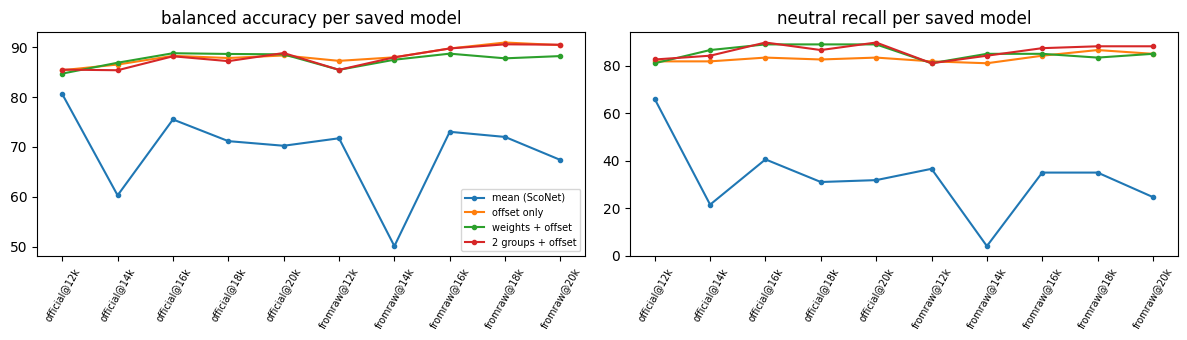

In [4]:
names = [f'{r}@{i}k' for r in ['official', 'fromraw'] for i in [12, 14, 16, 18, 20]]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for v in ['mean (ScoNet)', 'offset only', 'weights + offset', '2 groups + offset']:
    ax[0].plot(names, [m['bal'] for m in results_a[v]], '-o', ms=3, label=v)
    ax[1].plot(names, [m['rec_neu'] for m in results_a[v]], '-o', ms=3, label=v)
ax[0].set_title('balanced accuracy per saved model')
ax[1].set_title('neutral recall per saved model')
for a in ax:
    a.tick_params(axis='x', rotation=60, labelsize=7)
ax[0].legend(fontsize=7)
save_and_show(fig, '02_variants_per_model.png')

over all 10 models the 3 learned variants in the plot (offset only, weights + offset, 2 groups + offset) stay within ~3 points of each other, at 85-91 balanced accuracy, and all of them lift the bad checkpoints (official@14k 60 -> ~86, fromraw@14k 50 -> ~88) to the level of the good ones. so the stability gain i hoped for in notebook 02 (step 7) is real, but it comes from the **offset**, not from the strip weights.

step 3: which strips does it choose?

now i fit `weights + offset` once on **all** 749 children of `official@16k`, only to *look* at the learned weights (not to measure anything). if notebook 02 was right, neutral should get more weight in the middle / legs, and positive-vs-the-rest should use other strips.

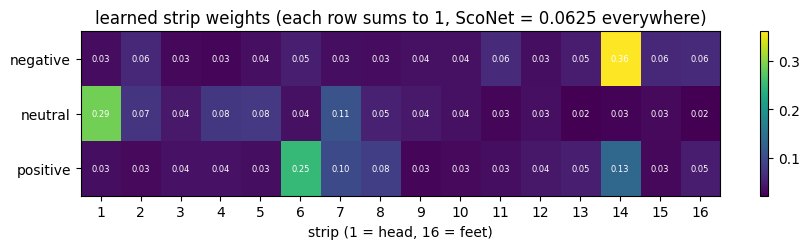

offset b (neg, neu, pos): [ 1.56 -1.33 -0.12]
upper body (1-8) share per class: [0.3  0.76 0.6 ]


In [5]:
cos16, y16, _ = load_saved_logits('official', 16000)
comb = fit_combiner(cos16, y16, 'weights + offset')
w = comb.weights().detach().numpy()
fig, ax = plt.subplots(figsize=(9, 2.6))
im = ax.imshow(w, cmap='viridis', aspect='auto')
ax.set_yticks(range(3), LABEL_NAMES)
ax.set_xticks(range(16), range(1, 17))
ax.set_xlabel('strip (1 = head, 16 = feet)')
for k in range(3):
    for s in range(16):
        ax.text(s, k, f'{w[k, s]:.2f}', ha='center', va='center', fontsize=6, color='w')
fig.colorbar(im)
ax.set_title('learned strip weights (each row sums to 1, ScoNet = 0.0625 everywhere)')
save_and_show(fig, '03_learned_weights.png')
print('offset b (neg, neu, pos):', comb.b.detach().numpy().round(2))
print('upper body (1-8) share per class:', w[:, :8].sum(1).round(2))

**the learned weights are very spiky**: negative puts 0.36 on strip 14, neutral 0.29 on strip 1 and positive 0.25 on strip 6, and everything else is near or below the ScoNet value 0.0625. neutral puts 76% of its weight on the upper body (strips 1-8) and negative only 30%. that's the opposite of what i expected from notebook 02 (the legs vote neutral more often), but that was about the *border* of each strip, and here the offset `b` (neutral -1.33, negative +1.56) takes care of the border, so the weights are free to pick whatever ranks best on these 749 children.

because the strips are so correlated, many very different weight patterns give almost the same answer. so i should **not** read these spikes as "strip 14 is the negative strip". they're one of many equivalent solutions, fitted on the test set, and the CV in step 2 showed that they don't generalise better than equal weights.

part B: strip weighting inside the network

part A only re-weights the answers of a model that was trained with equal strips. inside the network the weighting can also change **what the strips learn**. so i compare 3 heads on the same mini training (same children, same seed, balanced sampler so the imbalance doesn't hide the effect). **mean** is normal ScoNet-MT. **static weights** is one learned `a [3, 16]` for the whole dataset (the module from part A, but trained with the network). **dynamic weights** means the weights depend on the child: a small layer looks at every strip embedding (256 numbers) and gives a score per class, with a softmax over the 16 strips. that's an *attention over strips*, so a child whose legs are unusual can put more weight on the legs.

about the loss: if only the weighted answer got the cross entropy, a strip with a small weight would get almost no gradient and could stop learning (it "dies"). so i keep the normal ScoNet loss on **every strip** and add one more CE on the weighted answer:

`loss = triplet(child) + CE(every strip) + CE(weighted answer)`

In [6]:
class StaticStripWeights(nn.Module):
    def __init__(self, parts=16, classes=3):
        super().__init__()
        self.a = nn.Parameter(torch.zeros(classes, parts))

    def forward(self, embed, cos):                      # cos [n, 3, 16]
        w = torch.softmax(self.a, dim=1).unsqueeze(0).expand(cos.shape[0], -1, -1)
        return (cos * w).sum(-1), w


class DynamicStripWeights(nn.Module):
    def __init__(self, embed_dim=256, classes=3, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(embed_dim, hidden), nn.Tanh(), nn.Linear(hidden, classes))
        nn.init.zeros_(self.score[2].weight)            # start = equal weights = ScoNet
        nn.init.zeros_(self.score[2].bias)

    def forward(self, embed, cos):                      # embed [n, 256, 16]
        a = self.score(embed.permute(0, 2, 1).float())  # [n, 16, 3]
        w = torch.softmax(a.permute(0, 2, 1), dim=-1)   # [n, 3, 16], softmax over strips
        return (cos.float() * w).sum(-1), w


class ScoNetStrip(ScoNetMT):
    def __init__(self, mode='mean'):
        super().__init__()
        self.mode = mode
        self.combine = {'mean': None, 'static': StaticStripWeights(), 'dynamic': DynamicStripWeights()}[mode]

    def forward(self, sils):
        out = super().forward(sils)                     # embed [n, 256, 16], logits [n, 3, 16]
        if self.combine is None:
            out['fused'] = out['logits'].float().mean(-1)
            out['w'] = torch.full_like(out['logits'].float(), 1 / 16)
        else:
            out['fused'], out['w'] = self.combine(out['embed'], out['logits'])
        return out


def loss_strip(out, labels, pids):
    return triplet_loss(out['embed'], pids) + ce_loss(out['logits'], labels) + ce_loss(out['fused'], labels)


test_model = ScoNetStrip('dynamic')
x = torch.rand(2, 8, 64, 44)
o = test_model(x)
print({k: tuple(v.shape) for k, v in o.items()})
print('extra parameters: static', sum(p.numel() for p in StaticStripWeights().parameters()),
      '| dynamic', sum(p.numel() for p in DynamicStripWeights().parameters()))

{'embed': (2, 256, 16), 'logits': (2, 3, 16), 'fused': (2, 3), 'w': (2, 3, 16)}
extra parameters: static 48 | dynamic 16643


step 4: mini training

the training children are **40 / 40 / 40** from the 1:1:8 `TRAIN_SET` with a balanced sampler (3 per class x 2 copies), and the test children **40 / 40 / 40** from `TEST_SET` (the same test children as notebook 01). the ResNet9 starts from GaitBase (CASIA-B gait recognition), 500 iterations, Adam 1e-4, 16 frames. the prediction uses `fused` (the weighted answer), and for `mean` that's exactly ScoNet. with 120 test children one child = 0.83 points, and a 40-child class recall moves 2.5 points per child, so one seed is noisy and i only look at big differences.

**how the mini models are tested (important).** the models are trained on clips of 16 random frames. if i test them with all 300 frames at once, the max over frames gives much bigger values than the model ever saw in training. i checked this once on a plain ScoNet-MT mini model (same children as here): with all 300 frames it got **36.7%** (almost every child "negative"), and with 10 random 16-frame clips averaged it got **65.8%**. that's probably also why every test child became "neutral" in the checkpoint_1 self_learning notebooks. so `predict_mini` (in `tools/common.py`) now tests like training: **10 random clips of 16 frames per child, with the class scores averaged over the clips**. the full ScoNet-MT doesn't have this problem as much, because it trains for 16,000 iterations on 30 frames.

the newly added modules (heads, strip weights, attention, fusion) learn with lr 1e-3 and the pretrained ResNet9 with 1e-4, because in a first try with 1e-4 everywhere the new modules hardly moved in 500 iterations.

In [7]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))

mini = {}
for mode in ['mean', 'static', 'dynamic']:
    print('---', mode)
    set_seed(0)
    model = ScoNetStrip(mode)
    load_gaitbase_backbone(model.backbone)
    train_mini(model, mini_train, loss_fn=loss_strip, balanced=True, seed=0, log_every=250)
    y, scores, raw = predict_mini(model, mini_test, out_key='fused')
    mini[mode] = (y, 16 * scores, np.stack([r['w'] for r in raw]))

rows = []
for mode, (y, z, _) in mini.items():
    m = metrics(y, z.argmax(1))
    s = z[:, 1] - z[:, 0]
    m['auc'] = auc(s[y == 1], s[y == 0])
    rows.append((mode, m))
print_metrics(rows, 'mini test (40 per class), balanced sampler, 1 seed')
for mode, m in rows:
    print(f'{mode:10s} AUC neutral vs negative {m["auc"]:.3f}')

--- mean


iter  250 | loss 1.6760 | 91s


iter  500 | loss 0.8821 | 180s


--- static


iter  250 | loss 1.6773 | 85s


iter  500 | loss 0.8840 | 169s


--- dynamic


iter  250 | loss 1.6745 | 87s


iter  500 | loss 0.8829 | 177s


mini test (40 per class), balanced sampler, 1 seed
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
mean                               70.0     67.5     78.8     67.5     72.5     70.0     70.0
static                             67.5     67.5     77.5     67.5     70.0     65.0     67.5
dynamic                            67.5     65.0     78.8     65.0     67.5     70.0     67.5
mean       AUC neutral vs negative 0.853
static     AUC neutral vs negative 0.853
dynamic    AUC neutral vs negative 0.858


**all three heads are within 2.5 points of each other: mean 70.0, static 67.5, dynamic 67.5** (balanced sampler, 40 per class). that's 3 children, which is noise with 120 test children, and the AUC (neutral vs negative) is the same too: 0.853 / 0.853 / 0.858. with the clip test the plain ScoNet-MT mini model is now quite balanced (negative 67.5, neutral 72.5, positive 70.0), because the balanced training set and sampler already put the border in a balanced place.

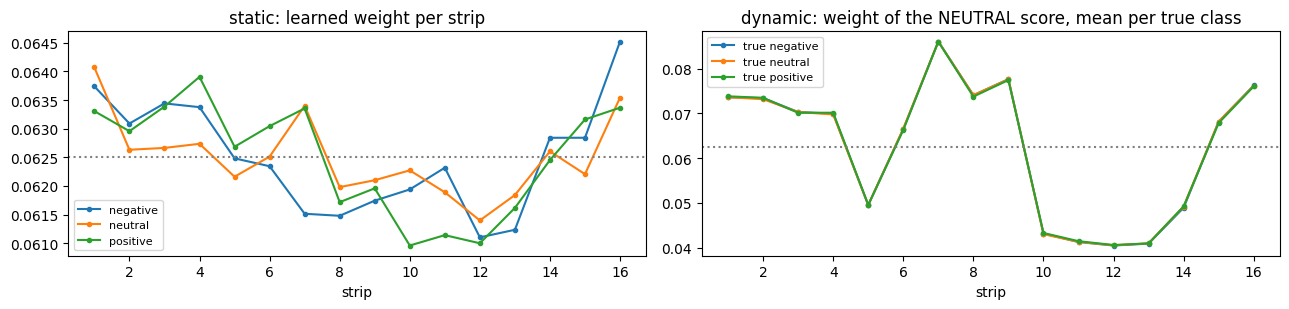

static weights, max / min: 0.065 / 0.061
dynamic weights, spread between children (std of the neutral weight per strip, mean): 0.0005


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
w_static = mini['static'][2][0]                         # the same for every child
for k in range(3):
    ax[0].plot(range(1, 17), w_static[k], '-o', ms=3, label=LABEL_NAMES[k])
ax[0].axhline(1 / 16, color='gray', ls=':')
ax[0].set_title('static: learned weight per strip')
ax[0].legend(fontsize=8)
y, _, w_dyn = mini['dynamic']
for c in range(3):
    ax[1].plot(range(1, 17), w_dyn[y == c, 1].mean(0), '-o', ms=3, label=f'true {LABEL_NAMES[c]}')
ax[1].axhline(1 / 16, color='gray', ls=':')
ax[1].set_title('dynamic: weight of the NEUTRAL score, mean per true class')
ax[1].legend(fontsize=8)
for a in ax:
    a.set_xlabel('strip')
save_and_show(fig, '04_mini_weights.png')
print('static weights, max / min:', w_static.max().round(3), '/', w_static.min().round(3))
print('dynamic weights, spread between children (std of the neutral weight per strip, mean):',
      w_dyn[:, 1].std(0).mean().round(4))

**the weights inside the network barely move: static 0.061-0.065** (ScoNet = 0.0625), and in the dynamic version the weights differ between children by only 0.0005 on average. so even with lr 1e-3 for the new modules, in 500 iterations the network keeps the weights almost equal.

my explanation: the strips are so correlated (notebook 02: ~2 opinions) that moving weight from one strip to another hardly changes the weighted answer, so the gradient on the weights is very small. and the CE on every single strip keeps all strips equally good, so there is no "bad strip" to switch off. so in this mini setup a learned strip weighting is **effectively the same model as ScoNet-MT**.

step 5: analysis

**1. does a learned strip weighting help?**

not as a weighting. on the saved logits the offset alone (3 numbers) gives the full gain (balanced 69.2 -> 88.3), and the 48 strip weights add nothing in CV and even lower the AUC a little. inside the network the weights stay almost equal (0.061-0.065), and the 3 heads are the same within noise.

**2. then why did the best strip window look so good in notebook 02?**

because it was chosen on the test set (upper limit), and because choosing strips also moves the border (the strips have different biases). once the border is fixed separately with an offset, choosing strips gives no extra ranking power.

**3. why don't the weights move inside the network?**

the strips are strongly correlated (n_eff ~ 2), so re-distributing the weight between them changes the answer very little and the gradient is tiny. the per-strip CE also trains every strip to be a good classifier on its own, so the plain mean of good, correlated classifiers is already close to the best mix.

**4. is a dynamic (per-child) weighting more promising than a static one?**

not in this setup, it learned to give every child almost the same weights. it might need a reason to differ between children (for example views, notebook 04), more data, or a loss only on the weighted answer, which carries the risk of dead strips.

**5. what does this mean for the 4 fixes of the plan?**

"equal strip averaging" is **not** a real weakness of ScoNet-MT. its problem is the border, which the class-imbalance fix (notebook 01) already handles. so i should drop learned strip weighting as a main contribution, or keep it only as an ablation showing that it's *not* needed.

**6. what are the limitations?**

- part A works on the test set (5-fold CV inside it), not on a separate val split.
- the saved logits come from models trained with equal strips, and a model trained from the start with a weighting might use its strips differently (part B tries this, but only in a small setting).
- part B is 1 seed, 500 iterations, 120 training children and a balanced sampler. with 16,000 iterations and the real imbalance the weights might move more.
- i didn't try other weighting forms (e.g. weights on the 256-d embeddings before the BNNeck, or a loss only on the weighted answer).
- the interpretation of the learned weights in step 3 is fitted on the whole test set and is not stable (many equivalent solutions).

what can we absorb into the new architecture?

i shouldn't build the new architecture around learned strip weights, because the evidence (CV on 10 models + mini training) says they don't add ranking power, so i keep the plain mean of strips. as the "decision layer" i use a **per-class offset (= logit adjustment with tau chosen on val)**, which is 3 numbers and gives the full gain and the stability (notebook 01 and part A here).

for the paper i can **report this as a negative result / ablation**, "strip weighting vs offset only". it answers a question a reviewer would ask ("why not learn the strip weights?"), and it supports the claim that ScoNet-MT's neutral problem is the border. if i still want something per strip, the more promising place is **inside the temporal model** (which frames feed which strip, notebook 04), not the final average.